In [1]:
import pandas as pd

In [3]:
df = pd.read_excel("data/Telco_customer_churn.xlsx")

In [4]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [5]:
df.shape

(7043, 33)

In [6]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

In [7]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

In [8]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

In [9]:
df['Total Charges'].dtype

dtype('float64')

In [10]:
df['Total Charges'].isnull().sum()

np.int64(11)

In [11]:
df['Total Charges'] = df['Total Charges'].fillna(0)

In [12]:
df['Total Charges'].isnull().sum()

np.int64(0)

In [13]:
df_kmeans = df.copy()

In [14]:
columnas_excluir = [
    'CustomerID',
    'Churn Label',
    'Churn Value',
    'Churn Score',
    'Churn Reason'
]

df_kmeans = df_kmeans.drop(columns=columnas_excluir)

In [15]:
df_kmeans.columns

Index(['Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude',
       'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV'],
      dtype='str')

In [16]:
columnas_ubicacion = [
    'Country',
    'State',
    'City',
    'Zip Code',
    'Lat Long',
    'Latitude',
    'Longitude'
]

df_kmeans = df_kmeans.drop(columns=columnas_ubicacion)

In [17]:
df_kmeans.columns

Index(['Count', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV'],
      dtype='str')

In [18]:
columnas_numericas = [
    'Count',
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

columnas_categoricas = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method'
]

In [19]:
df_kmeans['Count'].value_counts()

Count
1    7043
Name: count, dtype: int64

In [20]:
df_kmeans = df_kmeans.drop(columns=['Count'])

In [21]:
df_kmeans.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV'],
      dtype='str')

In [22]:
df_kmeans[columnas_numericas].dtypes

KeyError: "['Count'] not in index"

In [23]:
columnas_numericas = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

df_kmeans[columnas_numericas].dtypes

Tenure Months        int64
Monthly Charges    float64
Total Charges      float64
CLTV                 int64
dtype: object

In [24]:
columnas_numericas = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

df_kmeans[columnas_numericas].dtypes

Tenure Months        int64
Monthly Charges    float64
Total Charges      float64
CLTV                 int64
dtype: object

In [25]:
df_kmeans[columnas_categoricas].dtypes

Gender               str
Senior Citizen       str
Partner              str
Dependents           str
Phone Service        str
Multiple Lines       str
Internet Service     str
Online Security      str
Online Backup        str
Device Protection    str
Tech Support         str
Streaming TV         str
Streaming Movies     str
Contract             str
Paperless Billing    str
Payment Method       str
dtype: object

In [26]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas)
    ]
)

In [28]:
X_preparado = preprocessor.fit_transform(df_kmeans)

In [29]:
X_preparado.shape

(7043, 47)

In [30]:
from sklearn.cluster import KMeans

In [31]:
inercias = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_preparado)
    inercias.append(kmeans.inertia_)

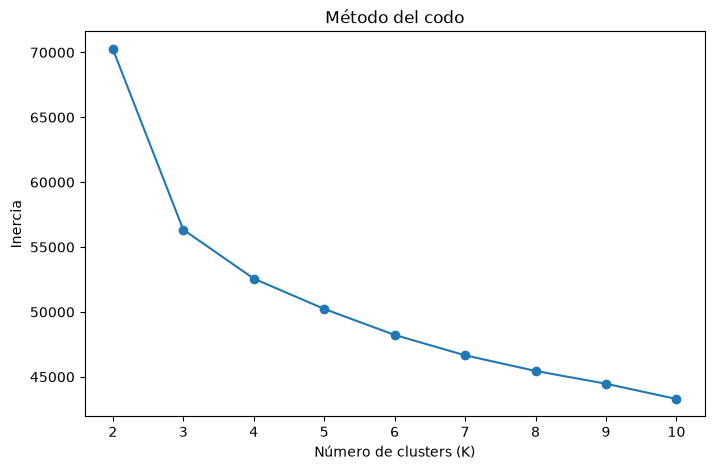

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inercias, marker='o')

plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.title('Método del codo')

plt.show()

In [33]:
for k, inercia in zip(range(2, 11), inercias):
    print(f"K={k}: Inercia={inercia:.2f}")

K=2: Inercia=70262.58
K=3: Inercia=56342.51
K=4: Inercia=52572.70
K=5: Inercia=50234.14
K=6: Inercia=48231.00
K=7: Inercia=46659.82
K=8: Inercia=45454.23
K=9: Inercia=44470.69
K=10: Inercia=43292.96


In [34]:
from sklearn.metrics import silhouette_score

siluetas = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    etiquetas = kmeans.fit_predict(X_preparado)
    
    score = silhouette_score(X_preparado, etiquetas)
    siluetas.append(score)
    
    print(f"K={k}: Silhouette={score:.4f}")

K=2: Silhouette=0.2340
K=3: Silhouette=0.2377
K=4: Silhouette=0.1929
K=5: Silhouette=0.1724
K=6: Silhouette=0.1407
K=7: Silhouette=0.1233
K=8: Silhouette=0.1213
K=9: Silhouette=0.1173
K=10: Silhouette=0.1083


In [35]:
k_final = 3

modelo_kmeans = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

df_kmeans['Cluster'] = modelo_kmeans.fit_predict(X_preparado)

In [36]:
df_kmeans['Cluster'].value_counts().sort_index()

Cluster
0    1526
1    3261
2    2256
Name: count, dtype: int64

In [37]:
k_final = 3

modelo_kmeans = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

df_kmeans['Cluster'] = modelo_kmeans.fit_predict(X_preparado)

In [38]:
df_kmeans['Cluster'].value_counts().sort_index()

Cluster
0    1526
1    3261
2    2256
Name: count, dtype: int64

In [39]:
df_kmeans.groupby('Cluster')[columnas_numericas].mean().round(2)

,Tenure Months,Monthly Charges,Total Charges,CLTV
Cluster,,,,
0,30.55,21.08,662.60,4374.38
1,15.56,68.63,1065.37,3974.63
2,57.90,88.72,5128.92,5033.11


In [40]:
df_kmeans.groupby('Cluster')[columnas_numericas].mean().round(2)

,Tenure Months,Monthly Charges,Total Charges,CLTV
Cluster,,,,
0,30.55,21.08,662.60,4374.38
1,15.56,68.63,1065.37,3974.63
2,57.90,88.72,5128.92,5033.11


In [41]:
for columna in ['Contract', 'Internet Service', 'Payment Method']:
    print(f"\n========== {columna} ==========")
    print(
        pd.crosstab(
            df_kmeans['Cluster'],
            df_kmeans[columna],
            normalize='index'
        ).round(2)
    )


========== Contract ==========
Contract  Month-to-month  One year  Two year
Cluster                                     
0                   0.34      0.24      0.42
1                   0.86      0.11      0.03
2                   0.24      0.33      0.43

========== Internet Service ==========
Internet Service   DSL  Fiber optic   No
Cluster                                 
0                 0.00         0.00  1.0
1                 0.47         0.53  0.0
2                 0.40         0.60  0.0

========== Payment Method ==========
Payment Method  Bank transfer (automatic)  Credit card (automatic)  \
Cluster                                                              
0                                    0.22                     0.22   
1                                    0.15                     0.15   
2                                    0.32                     0.31   

Payment Method  Electronic check  Mailed check  
Cluster                                         
0          

In [42]:
servicios = [
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies'
]

for columna in servicios:
    print(f"\n========== {columna} ==========")
    print(
        pd.crosstab(
            df_kmeans['Cluster'],
            df_kmeans[columna],
            normalize='index'
        ).round(2)
    )


========== Online Security ==========
Online Security    No  No internet service   Yes
Cluster                                         
0                0.00                  1.0  0.00
1                0.76                  0.0  0.24
2                0.45                  0.0  0.55

========== Online Backup ==========
Online Backup    No  No internet service   Yes
Cluster                                       
0              0.00                  1.0  0.00
1              0.73                  0.0  0.27
2              0.32                  0.0  0.68

========== Device Protection ==========
Device Protection    No  No internet service   Yes
Cluster                                           
0                  0.00                  1.0  0.00
1                  0.74                  0.0  0.26
2                  0.30                  0.0  0.70

========== Tech Support ==========
Tech Support    No  No internet service   Yes
Cluster                                      
0             0.00  

In [43]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_preparado)

X_pca.shape

(7043, 2)

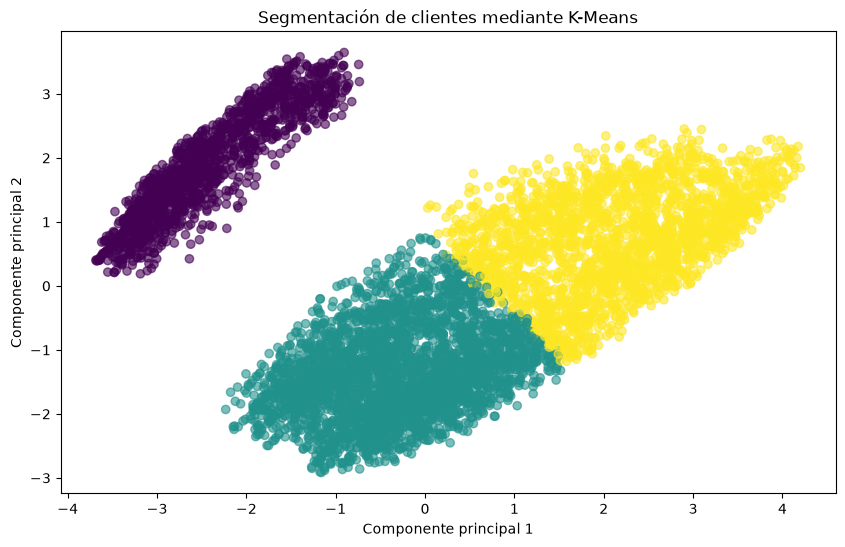

In [44]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df_kmeans['Cluster'],
    alpha=0.6
)

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Segmentación de clientes mediante K-Means')

plt.show()

In [45]:
print("Varianza explicada por cada componente:")
print(pca.explained_variance_ratio_)

print("\nVarianza explicada acumulada:")
print(pca.explained_variance_ratio_.sum())

Varianza explicada por cada componente:
[0.27083467 0.18394631]

Varianza explicada acumulada:
0.45478097902513664


In [46]:
resumen_clusters = df_kmeans.groupby('Cluster').agg(
    Clientes=('Cluster', 'size'),
    Antiguedad_promedio=('Tenure Months', 'mean'),
    Cargo_mensual_promedio=('Monthly Charges', 'mean'),
    Gasto_total_promedio=('Total Charges', 'mean'),
    CLTV_promedio=('CLTV', 'mean')
).round(2)

resumen_clusters

,Clientes,Antiguedad_promedio,Cargo_mensual_promedio,Gasto_total_promedio,CLTV_promedio
Cluster,,,,,
0,1526,30.55,21.08,662.60,4374.38
1,3261,15.56,68.63,1065.37,3974.63
2,2256,57.90,88.72,5128.92,5033.11


In [47]:
df_resultado = df.copy()

df_resultado['Cluster'] = modelo_kmeans.labels_

df_resultado.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason,Cluster
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer,1
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved,1
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved,1
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved,2
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices,2


In [48]:
df_resultado.shape

(7043, 34)

In [49]:
df_resultado['Cluster'].value_counts().sort_index()

Cluster
0    1526
1    3261
2    2256
Name: count, dtype: int64

In [50]:
df_resultado.to_csv('data/clientes_segmentados.csv', index=False)

print("Archivo guardado correctamente.")

Archivo guardado correctamente.


In [51]:
df_verificacion = pd.read_csv('data/clientes_segmentados.csv')

print("Tamaño del archivo:", df_verificacion.shape)
print("\nColumnas:")
print(df_verificacion.columns.tolist())

Tamaño del archivo: (7043, 34)

Columnas:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason', 'Cluster']


In [52]:
df_verificacion['Cluster'].value_counts().sort_index()

Cluster
0    1526
1    3261
2    2256
Name: count, dtype: int64

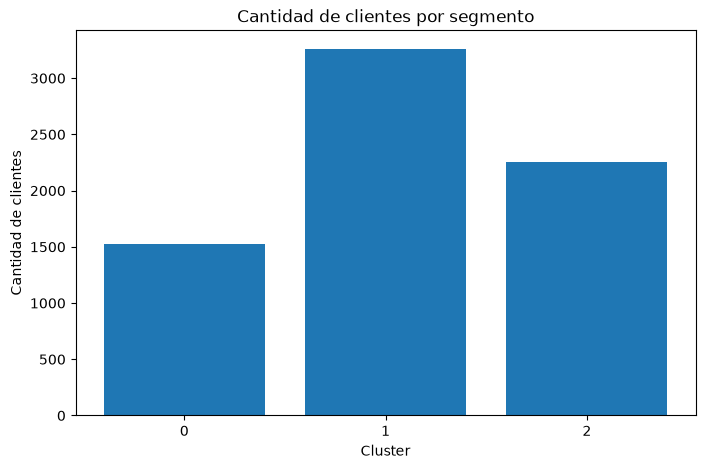

In [53]:
import matplotlib.pyplot as plt

clientes_por_cluster = df_resultado['Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    clientes_por_cluster.index.astype(str),
    clientes_por_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.title('Cantidad de clientes por segmento')

plt.show()

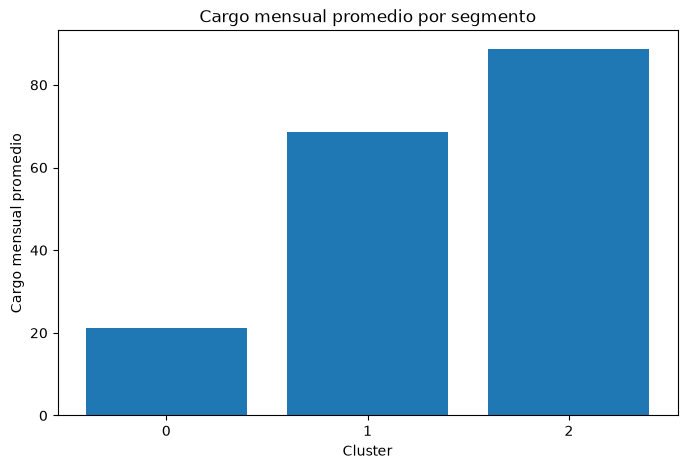

In [54]:
gasto_mensual_cluster = df_resultado.groupby('Cluster')['Monthly Charges'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    gasto_mensual_cluster.index.astype(str),
    gasto_mensual_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Cargo mensual promedio')
plt.title('Cargo mensual promedio por segmento')

plt.show()

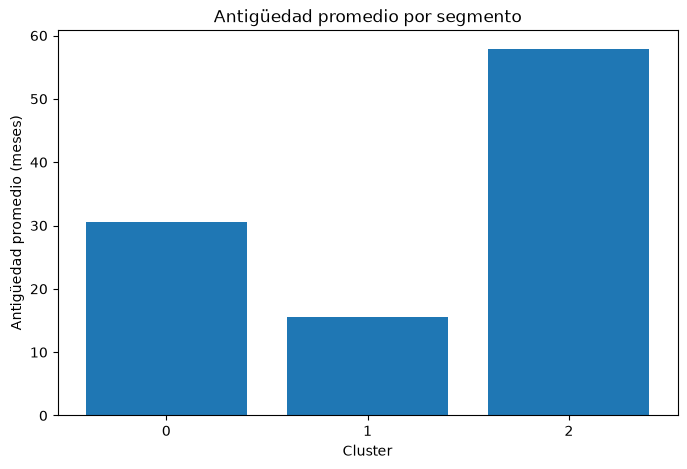

In [55]:
antiguedad_cluster = df_resultado.groupby('Cluster')['Tenure Months'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    antiguedad_cluster.index.astype(str),
    antiguedad_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Antigüedad promedio (meses)')
plt.title('Antigüedad promedio por segmento')

plt.show()

In [56]:
resumen_final = df_resultado.groupby('Cluster').agg(
    Clientes=('Cluster', 'size'),
    Antiguedad_promedio=('Tenure Months', 'mean'),
    Cargo_mensual_promedio=('Monthly Charges', 'mean'),
    Gasto_total_promedio=('Total Charges', 'mean'),
    CLTV_promedio=('CLTV', 'mean')
).round(2)

resumen_final

,Clientes,Antiguedad_promedio,Cargo_mensual_promedio,Gasto_total_promedio,CLTV_promedio
Cluster,,,,,
0,1526,30.55,21.08,662.60,4374.38
1,3261,15.56,68.63,1065.37,3974.63
2,2256,57.90,88.72,5128.92,5033.11


In [57]:
perfil_contrato = pd.crosstab(
    df_resultado['Cluster'],
    df_resultado['Contract'],
    normalize='index'
).round(2)

perfil_contrato

Contract,Month-to-month,One year,Two year
Cluster,,,
0,0.34,0.24,0.42
1,0.86,0.11,0.03
2,0.24,0.33,0.43


In [58]:
perfil_internet = pd.crosstab(
    df_resultado['Cluster'],
    df_resultado['Internet Service'],
    normalize='index'
).round(2)

perfil_internet

Internet Service,DSL,Fiber optic,No
Cluster,,,
0,0.00,0.00,1.0
1,0.47,0.53,0.0
2,0.40,0.60,0.0


In [59]:
servicios = [
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies'
]

perfil_servicios = {}

for servicio in servicios:
    porcentaje_si = (
        df_resultado.groupby('Cluster')[servicio]
        .apply(lambda x: (x == 'Yes').mean())
    )
    
    perfil_servicios[servicio] = porcentaje_si

perfil_servicios = pd.DataFrame(perfil_servicios).round(2)

perfil_servicios

,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies
Cluster,,,,,,
0,0.00,0.00,0.00,0.00,0.00,0.00
1,0.24,0.27,0.26,0.23,0.33,0.33
2,0.55,0.68,0.70,0.58,0.72,0.73


FileNotFoundError: [Errno 2] No such file or directory: 'graficas/clientes_por_segmento.png'

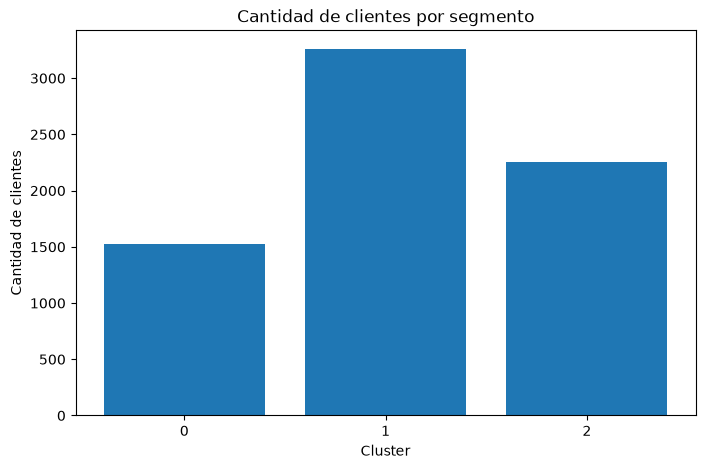

In [60]:
clientes_por_cluster = df_resultado['Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    clientes_por_cluster.index.astype(str),
    clientes_por_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.title('Cantidad de clientes por segmento')

plt.savefig('graficas/clientes_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

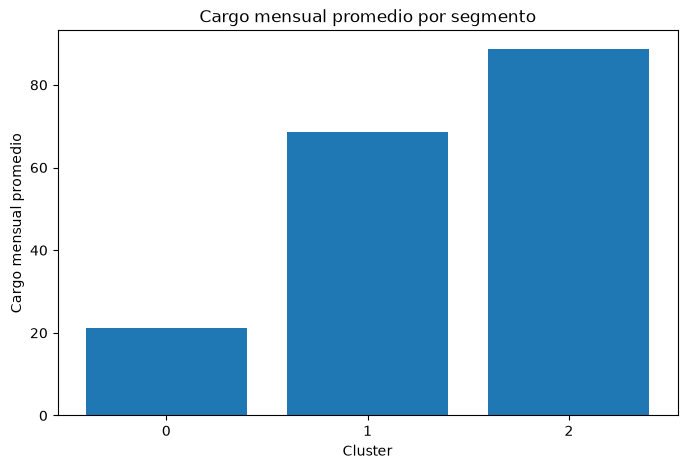

In [70]:
gasto_mensual_cluster = df_resultado.groupby('Cluster')['Monthly Charges'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    gasto_mensual_cluster.index.astype(str),
    gasto_mensual_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Cargo mensual promedio')
plt.title('Cargo mensual promedio por segmento')

plt.savefig('graficas/cargo_mensual_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

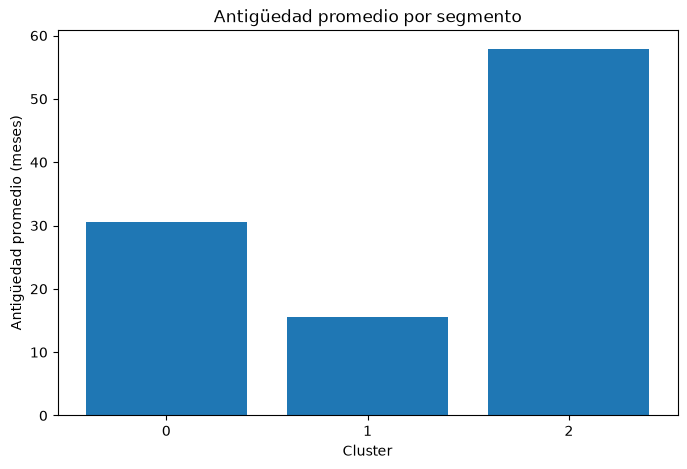

In [69]:
antiguedad_cluster = df_resultado.groupby('Cluster')['Tenure Months'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    antiguedad_cluster.index.astype(str),
    antiguedad_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Antigüedad promedio (meses)')
plt.title('Antigüedad promedio por segmento')

plt.savefig('graficas/antiguedad_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

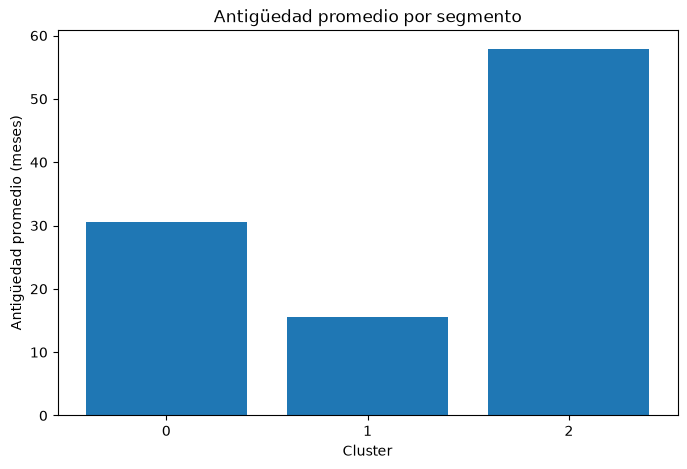

In [68]:
antiguedad_cluster = df_resultado.groupby('Cluster')['Tenure Months'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    antiguedad_cluster.index.astype(str),
    antiguedad_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Antigüedad promedio (meses)')
plt.title('Antigüedad promedio por segmento')

plt.savefig('graficas/antiguedad_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

In [64]:
import os

os.makedirs('graficas', exist_ok=True)

print("Carpeta 'graficas' lista.")

Carpeta 'graficas' lista.


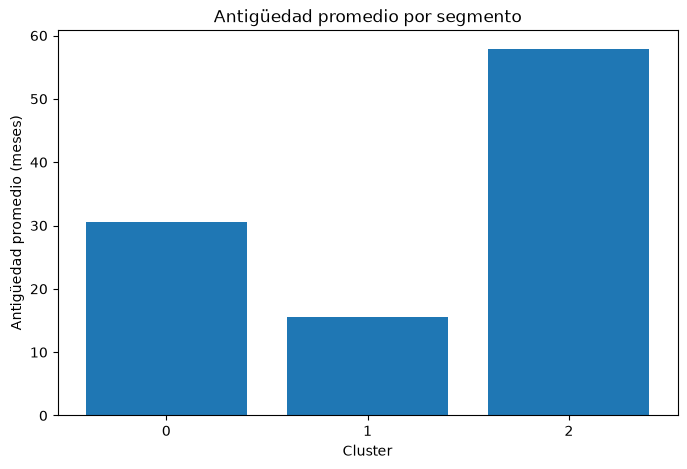

In [71]:
antiguedad_cluster = df_resultado.groupby('Cluster')['Tenure Months'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    antiguedad_cluster.index.astype(str),
    antiguedad_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Antigüedad promedio (meses)')
plt.title('Antigüedad promedio por segmento')

plt.savefig('graficas/antiguedad_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

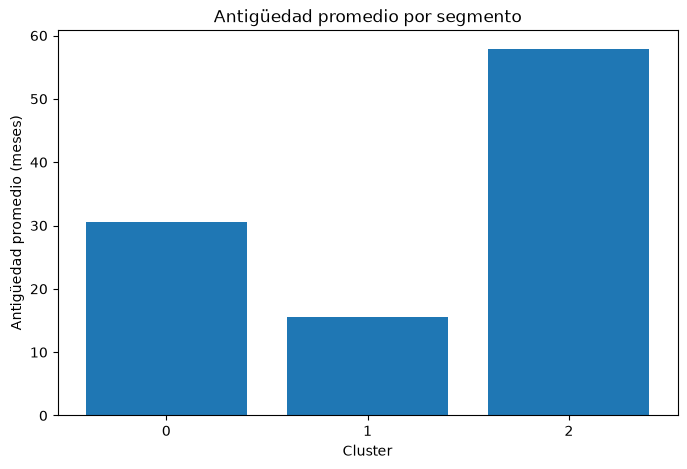

In [72]:
antiguedad_cluster = df_resultado.groupby('Cluster')['Tenure Months'].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    antiguedad_cluster.index.astype(str),
    antiguedad_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Antigüedad promedio (meses)')
plt.title('Antigüedad promedio por segmento')

plt.savefig('graficas/antiguedad_por_segmento.png', dpi=300, bbox_inches='tight')

plt.show()

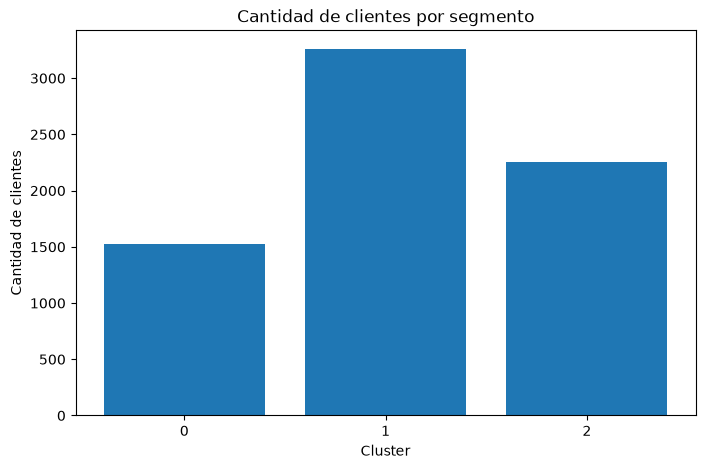

In [73]:
clientes_por_cluster = df_resultado['Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    clientes_por_cluster.index.astype(str),
    clientes_por_cluster.values
)

plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.title('Cantidad de clientes por segmento')

plt.savefig(
    'graficas/clientes_por_segmento.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()